## Gather data for Arivale-SWS study

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator
from regression_functions import *
from tableone import TableOne
from scipy.stats import spearmanr


import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()

In [3]:
abx_covar = pd.read_csv("data/abx_recency_covariates_all.csv",
                        dtype={"public_client_id":str, "days_in_program":float})

In [4]:
abx_covar['abx_year'] = abx_covar['abx_recency'].apply(lambda x: "none" if x == "none" else "past_year")

In [5]:
clients = adi.get_snapshot('clients')
sws = clients[clients.latest_program == 'Arivale-Providence Feasibility Study of Scientific Wellness'].copy()
abx_sws_overlap = abx_covar[abx_covar.public_client_id.isin(sws.public_client_id)].copy()
abx_sws_overlap.abx_recency.value_counts()

abx_recency
none      495
twelve    178
three     130
Name: count, dtype: int64

In [6]:
abx_sws_overlap.days_in_program.describe()

count    803.000000
mean      11.322540
std       51.335281
min        0.000000
25%        0.000000
50%        2.000000
75%        8.000000
max      752.000000
Name: days_in_program, dtype: float64

## Make TableOne

In [7]:
columns = ['age', 'sex', 'BMI_CALC', 'eGFR', 'meds_blood_sugar', 'meds_cholesterol']
continuous = ['age','BMI_CALC', 'eGFR']
categorical = ['sex', 'meds_blood_sugar', 'meds_cholesterol']
groupby = 'abx_year'

table1 = TableOne(abx_sws_overlap, columns=columns, 
                  categorical=categorical, continuous=continuous,
                  groupby=groupby, pval=True, htest_name=True)
table1

Grouped by abx_year                                                               
                                        Missing      Overall         none    past_year P-Value            Test
n                                                        803          495          308                        
age, mean (SD)                                0  47.7 (10.3)  47.6 (10.2)  47.8 (10.5)   0.739  Welch’s T-test
sex, n (%)              F                         618 (77.0)   369 (74.5)   249 (80.8)   0.048     Chi-squared
                        M                         185 (23.0)   126 (25.5)    59 (19.2)                        
BMI_CALC, mean (SD)                           0   29.3 (7.0)   28.6 (6.5)   30.4 (7.4)  <0.001  Welch’s T-test
eGFR, mean (SD)                               0  97.1 (14.4)  96.9 (14.4)  97.4 (14.4)   0.653  Welch’s T-test
meds_blood_sugar, n (%) No                        754 (93.9)   471 (95.2)   283 (91.9)   0.084     Chi-squared
                        Yes                         49 (6.1)     24 (4.8)     25 (8.1)                        
meds_cholesterol, n (%) No                        716 (89.2)   453 (91.5)   263 (85.4)   0.009     Chi-squared
                        Yes                        87 (10.8)     42 (8.5)    45 (14.6)

In [8]:
excel_table = 'figures/tableone_arivale_sws_antibiotics.xlsx'
table1.to_excel(excel_table)

## Let's identify our statin users

In [9]:
statin_users = pd.read_csv('data/arivale_statin_users.csv', dtype={"public_client_id":str, "days_in_program":float})
statin_users = statin_users.sort_values(by="days_in_program")
abx_sws_overlap = abx_sws_overlap.sort_values(by="days_in_program")

In [10]:
statin_users = statin_users.sort_values(by="days_in_program")
abx_sws_overlap = abx_sws_overlap.sort_values(by="days_in_program")

In [11]:
# Merge with all
sws_statins = pd.merge_asof(
    abx_sws_overlap, statin_users, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30)

In [12]:
# sws_statins

In [13]:
pd.crosstab(sws_statins['meds_cholesterol'], sws_statins['statin'])

statin,atorvastatin,fluvastatin,lovastatin,pravastatin,rosuvastatin,simvastatin
meds_cholesterol,,,,,,
No,0,0,1,0,0,0
Yes,35,1,5,5,3,13


In [14]:
sws_statins.loc[
(sws_statins['meds_cholesterol'] == 'No') &
(sws_statins.statin.notna()), 'meds_cholesterol'] = 'Yes'

In [15]:
pd.crosstab(sws_statins['meds_cholesterol'], sws_statins['statin'])

statin,atorvastatin,fluvastatin,lovastatin,pravastatin,rosuvastatin,simvastatin
meds_cholesterol,,,,,,
Yes,35,1,6,5,3,13


In [16]:
sws_statins['statin_binary'] = sws_statins['statin'].notna().astype(int)

## Add clinical chemistries to this cohort

In [17]:
labs_clean = pd.read_csv("data/clincal_chems_abx_users_clean.csv", 
                         dtype={"public_client_id":str, "days_in_program":float})

labs_clean.set_index(['public_client_id','days_in_program'], inplace=True)

labs = ['HOMA_IR', 'QUICKI', 'GLYCOHEMOGLOBINA1C',
        'HDLPARTICLENUMBER', 'LDLPARTICLENUMBER', 'vendor']

labs_clean_small = labs_clean[labs]

sws_statins_labs = pd.merge_asof(
    sws_statins,
    labs_clean_small,
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30)

In [29]:
sws_statins_labs.abx_year

0           none
1      past_year
2           none
3           none
4           none
         ...    
798         none
799    past_year
800    past_year
801    past_year
802    past_year
Name: abx_year, Length: 803, dtype: object

In [19]:
# sws_statins_labs.dropna(subset=['statin_binary','GLYCOHEMOGLOBINA1C'])

1_none vs. 1_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.683e-01 U_stat=3.600e+02
0_none vs. 0_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.882e-02 U_stat=4.052e+04
0_none vs. 1_none: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.286e-04 U_stat=3.219e+03
0_past_year vs. 1_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.857e-03 U_stat=2.013e+03


(<Axes: xlabel='statin_binary', ylabel='HOMA_IR'>,
  <statannotations.Annotation.Annotation at 0x78bc2c1b0e60>])

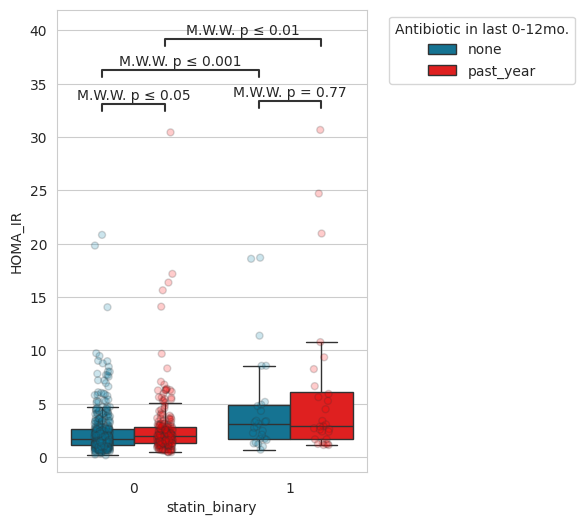

In [43]:
sns.set_style(style="whitegrid")
abx_order = ['none', 'past_year']
abx_year_pal = {'none': "#007ea7", 'past_year': 'red'}

statin_order = [0, 1]
comparisons=[
    ((0, 'none'), (0, 'past_year')),
    ((1,'none'),(1, 'past_year')),
    ((0, 'none'), (1, 'none')),
    ((0, 'past_year'), (1, 'past_year')),
    ]

fig, ax = plt.subplots(1, 1, figsize=(4, 6))
sns.boxplot(data=sws_statins_labs, x='statin_binary', y ='HOMA_IR',
            hue='abx_year', showfliers=False, palette=abx_year_pal,
            order=statin_order, hue_order=abx_order)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Antibiotic in last 0-12mo.")

sns.stripplot(data=sws_statins_labs, x='statin_binary', y ='HOMA_IR',
              hue='abx_year',  palette=abx_year_pal, 
              order=statin_order, hue_order=abx_order,
              alpha=0.2, jitter=True, dodge=True, legend=False,
              marker="o",          # Standard circle marker
              facecolors="none",   # Removes the fill (makes it open)
              linewidth=1)

# Annotate
annotator = Annotator(ax, comparisons, data=sws_statins_labs, x='statin_binary', y='HOMA_IR',
               order=statin_order, hue='abx_year', hue_order=abx_order)
annotator.configure(test='Mann-Whitney', verbose=2, comparisons_correction="BH", text_format='simple')
annotator.apply_test() 
annotator.annotate()

In [37]:
sws_statins_labs_t2dm = sws_statins_labs[sws_statins_labs.gluc_dysreg == 1]
sws_statins_labs_hc = sws_statins_labs[sws_statins_labs.gluc_dysreg == 0]

1_none vs. 1_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.623e-01 U_stat=3.650e+01
0_none vs. 0_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.005e-01 U_stat=3.220e+02
0_none vs. 1_none: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.780e-02 (ns) U_stat=4.300e+01
0_past_year vs. 1_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.874e-02 (ns) U_stat=6.300e+01


(<Axes: xlabel='statin_binary', ylabel='GLYCOHEMOGLOBINA1C'>,
  <statannotations.Annotation.Annotation at 0x78bc20d16300>])

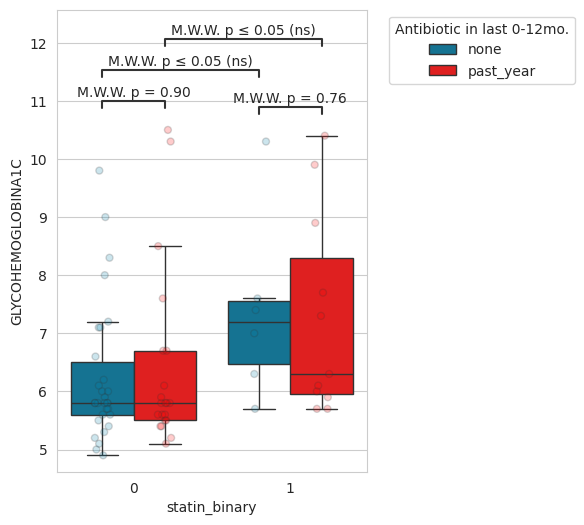

In [46]:
fig, ax = plt.subplots(1, 1, figsize=(4, 6))
sns.boxplot(data=sws_statins_labs_t2dm, x='statin_binary', y ='GLYCOHEMOGLOBINA1C',
            hue='abx_year', showfliers=False, palette=abx_year_pal,
            order=statin_order, hue_order=abx_order)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Antibiotic in last 0-12mo.")

sns.stripplot(data=sws_statins_labs_t2dm, x='statin_binary', y ='GLYCOHEMOGLOBINA1C',
              hue='abx_year',  palette=abx_year_pal, 
              order=statin_order, hue_order=abx_order,
              alpha=0.2, jitter=True, dodge=True, legend=False,
              marker="o",          # Standard circle marker
              facecolors="none",   # Removes the fill (makes it open)
              linewidth=1)

# Annotate
annotator = Annotator(ax, comparisons, data=sws_statins_labs_t2dm, x='statin_binary', y='GLYCOHEMOGLOBINA1C',
               order=statin_order, hue='abx_year', hue_order=abx_order)
annotator.configure(test='Mann-Whitney', verbose=2, comparisons_correction="BH", text_format='simple')
annotator.apply_test() 
annotator.annotate()

1_none vs. 1_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.993e-01 U_stat=1.650e+02
0_none vs. 0_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.823e-01 U_stat=3.701e+04
0_none vs. 1_none: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.436e-02 (ns) U_stat=2.925e+03
0_past_year vs. 1_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.777e-02 (ns) U_stat=1.137e+03


(<Axes: xlabel='statin_binary', ylabel='GLYCOHEMOGLOBINA1C'>,
  <statannotations.Annotation.Annotation at 0x78bc20d38410>])

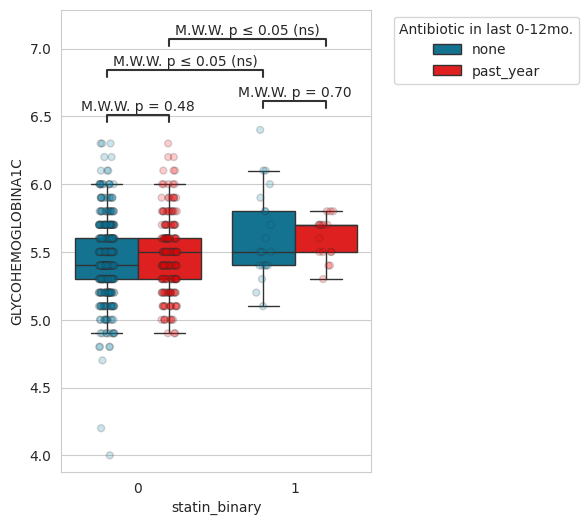

In [47]:
fig, ax = plt.subplots(1, 1, figsize=(4, 6))
sns.boxplot(data=sws_statins_labs_hc, x='statin_binary', y ='GLYCOHEMOGLOBINA1C',
            hue='abx_year', showfliers=False, palette=abx_year_pal,
            order=statin_order, hue_order=abx_order)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Antibiotic in last 0-12mo.")

sns.stripplot(data=sws_statins_labs_hc, x='statin_binary', y ='GLYCOHEMOGLOBINA1C',
              hue='abx_year',  palette=abx_year_pal, 
              order=statin_order, hue_order=abx_order,
              alpha=0.2, jitter=True, dodge=True, legend=False,
              marker="o",          # Standard circle marker
              facecolors="none",   # Removes the fill (makes it open)
              linewidth=1)

# Annotate
annotator = Annotator(ax, comparisons, data=sws_statins_labs_hc, x='statin_binary', y='GLYCOHEMOGLOBINA1C',
               order=statin_order, hue='abx_year', hue_order=abx_order)
annotator.configure(test='Mann-Whitney', verbose=2, comparisons_correction="BH", text_format='simple')
annotator.apply_test() 
annotator.annotate()

In [48]:
hba1c_statin_abx = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                    'PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) +'
                    'C(statin_binary)*C(abx_year) + C(meds_blood_sugar) + C(hx_t2dm) + C(hx_gestational)')

hba1c_model = ols(hba1c_statin_abx, data=sws_statins_labs).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.544
Model:                            OLS   Adj. R-squared:                  0.533
Method:                 Least Squares   F-statistic:                     53.22
Date:                Mon, 20 Jul 2026   Prob (F-statistic):          2.06e-103
Time:                        20:30:21   Log-Likelihood:                -384.33
No. Observations:                 686   AIC:                             800.7
Df Residuals:                     670   BIC:                             873.2
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
==================================================================================================================
                                                     coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------
Intercept                                          4.7537      0.115     41.501      0.000       4.529       4.979
C(sex)[T.M]                                        0.0259      0.041      0.634      0.526      -0.054       0.106
C(statin_binary)[T.1]                              0.0515      0.089      0.582      0.561      -0.122       0.225
C(abx_year)[T.past_year]                           0.0149      0.036      0.409      0.683      -0.056       0.086
C(meds_blood_sugar)[T.Yes]                         0.5393      0.099      5.434      0.000       0.344       0.734
C(hx_t2dm)[T.Yes]                                  1.4429      0.120     11.982      0.000       1.206       1.679
C(hx_gestational)[T.Yes]                          -0.0087      0.086     -0.102      0.919      -0.178       0.160
C(statin_binary)[T.1]:C(abx_year)[T.past_year]     0.0232      0.122      0.190      0.850      -0.217       0.263
age                                                0.0067      0.002      3.571      0.000       0.003       0.010
BMI_CALC                                           0.0138      0.002      5.521      0.000       0.009       0.019
centered_eGFR                                     -0.0009      0.001     -0.694      0.488      -0.004       0.002
PC1                                               -0.4932      0.140     -3.515      0.000      -0.769      -0.218
PC2                                                0.1978      0.102      1.947      0.052      -0.002       0.397
PC3                                                0.3211      0.173      1.854      0.064      -0.019       0.661
PC4                                                0.0410      0.150      0.273      0.785      -0.254       0.336
PC5                                               -0.1821      0.105     -1.727      0.085      -0.389       0.025
==============================================================================
Omnibus:                      383.568   Durbin-Watson:                   2.083
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            11460.498
Skew:                           1.925   Prob(JB):                         0.00
Kurtosis:                      22.650   Cond. No.                         617.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [49]:
# g = sns.catplot(
#     data=sws_statins_labs,
#     # kind="box",
#     x="abx_year",
#     y="GLYCOHEMOGLOBINA1C",
#     col="gluc_dysreg",    
#     hue="statin_binary",
#     order=['none', 'past_year'],
#     dodge=True,
#     height=4,
#     aspect=1.2
# )
# g.set_axis_labels("Antibiotic Use in Previous Year")

In [50]:
## Add Bacteroides
abx_microbes = pd.read_csv('data/rh_microbes_clr.csv', dtype={'public_client_id':str})
abx_microbes = abx_microbes.set_index('public_client_id')
abx_microbes = abx_microbes.iloc[:, 26:]
abx_microbes.reset_index(inplace = True)

In [51]:
# Merge with measure
abx_microbes_labs = sws_statins_labs.merge(
    abx_microbes,
    how='left',
    on="public_client_id").dropna(
    subset="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides")
abx_microbes_labs

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Oxalobacter,Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Parasutterella,Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Sutterella,Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Escherichia_Shigella,Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Klebsiella,Bacteria_Proteobacteria_Gammaproteobacteria_Pasteurellales_Pasteurellaceae_Haemophilus,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Cloacibacillus,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia
0,01167099,0.064411,-0.025370,-0.029556,0.044585,0.031527,0.0,No,No,none,...,NaN,6.065904,7.949486,4.781308,4.195406,NaN,NaN,NaN,NaN,6.893235
1,01547734,0.055882,-0.003758,-0.003902,-0.051229,0.017108,0.0,No,No,three,...,NaN,6.844321,7.248878,NaN,NaN,3.742320,NaN,NaN,NaN,NaN
3,01564778,-0.127559,0.510501,-0.107291,0.096867,0.061096,0.0,No,No,none,...,NaN,4.937919,6.864536,4.403462,NaN,2.184258,NaN,NaN,NaN,6.397866
4,01565346,0.063450,-0.021086,-0.019732,0.051706,0.030837,0.0,No,No,none,...,NaN,3.933506,NaN,6.863674,NaN,NaN,7.296816,NaN,NaN,9.371251
5,01566332,0.062006,-0.010562,-0.049711,0.059184,0.018954,0.0,No,No,none,...,NaN,NaN,NaN,2.752467,NaN,2.529323,NaN,6.063010,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
797,01319136,0.070725,-0.016916,-0.051444,0.038110,0.023882,216.0,Yes,No,three,...,NaN,NaN,7.848195,NaN,NaN,3.220425,NaN,NaN,NaN,NaN
799,01726684,0.063963,-0.027301,-0.038506,0.085400,0.007325,408.0,No,Yes,three,...,NaN,NaN,8.096503,NaN,NaN,3.137551,NaN,NaN,NaN,7.921332
800,01201199,0.065988,-0.013680,-0.050926,0.044681,0.035107,712.0,No,No,three,...,NaN,7.075396,NaN,NaN,NaN,NaN,NaN,4.289014,4.449944,NaN
801,01440344,-0.490879,-0.196570,-0.115884,-0.019040,0.133794,731.0,No,Yes,three,...,NaN,8.442398,NaN,5.212057,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
pd.crosstab(abx_microbes_labs['statin_binary'], abx_microbes_labs['gluc_dysreg'])

gluc_dysreg,0,1
statin_binary,,
0,506,47
1,29,12


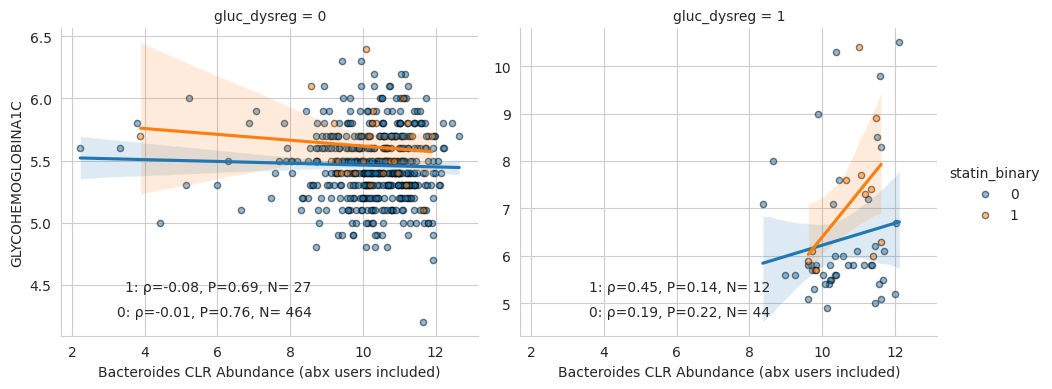

In [53]:
g = sns.lmplot(
    data=abx_microbes_labs,
    x="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides",
    y="GLYCOHEMOGLOBINA1C",
    col="gluc_dysreg",
    hue="statin_binary",
    scatter_kws={
        "s": 20,
        "edgecolor": "black",
        "alpha": 0.5
    },
    facet_kws={"sharey": False},
    height=4,
    aspect=1.2
)
g.set_axis_labels("Bacteroides CLR Abundance (abx users included)")

# Loop through each facet
for (col_val), ax in g.axes_dict.items():
    facet_df = abx_microbes_labs[(abx_microbes_labs["gluc_dysreg"] == col_val)]
    y = 0.1   # starting height for annotations

    for hue_val in facet_df["statin_binary"].unique():

        subset = facet_df[facet_df["statin_binary"] == hue_val][[
                "Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides", "GLYCOHEMOGLOBINA1C"]].dropna()

        if len(subset) > 2:
            rho, p = spearmanr(subset["Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides"], subset["GLYCOHEMOGLOBINA1C"])
            n_hue = len(subset)

            ax.text(
                0.6, y,
                f"{hue_val}: ρ={rho:.2f}, P={p:.2g}, N={n_hue: .4g}",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=10
            )

            y += 0.08

In [55]:
abx_microbes_labs['centered_bac_clr'] = abx_microbes_labs['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides'].apply(
    lambda x: x - (abx_microbes_labs['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides']).mean())

In [56]:
hba1c_statin_abx = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                    'PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) +'
                    'C(statin_binary)*C(gluc_dysreg)*centered_bac_clr + C(abx_year)')

hba1c_model = ols(hba1c_statin_abx, data=abx_microbes_labs).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.398
Model:                            OLS   Adj. R-squared:                  0.379
Method:                 Least Squares   F-statistic:                     20.58
Date:                Mon, 20 Jul 2026   Prob (F-statistic):           6.14e-48
Time:                        20:31:09   Log-Likelihood:                -375.34
No. Observations:                 547   AIC:                             786.7
Df Residuals:                     529   BIC:                             864.2
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
==============================================================================================================================
                                                                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------
Intercept                                                      4.4608      0.143     31.086      0.000       4.179       4.743
C(sex)[T.M]                                                    0.0993      0.054      1.823      0.069      -0.008       0.206
C(statin_binary)[T.1]                                          0.0190      0.101      0.188      0.851      -0.179       0.217
C(gluc_dysreg)[T.1]                                            0.7569      0.083      9.173      0.000       0.595       0.919
C(abx_year)[T.past_year]                                      -0.0050      0.045     -0.111      0.912      -0.094       0.084
C(statin_binary)[T.1]:C(gluc_dysreg)[T.1]                      0.1816      0.211      0.862      0.389      -0.232       0.595
age                                                            0.0092      0.002      3.877      0.000       0.005       0.014
BMI_CALC                                                       0.0193      0.003      6.015      0.000       0.013       0.026
centered_eGFR                                                  0.0016      0.002      0.892      0.373      -0.002       0.005
PC1                                                           -0.3509      0.180     -1.945      0.052      -0.705       0.004
PC2                                                            0.1266      0.135      0.934      0.350      -0.140       0.393
PC3                                                           -0.0967      0.243     -0.398      0.691      -0.574       0.380
PC4                                                           -0.0369      0.196     -0.188      0.851      -0.422       0.349
PC5                                                           -0.0199      0.138     -0.145      0.885      -0.290       0.250
centered_bac_clr                                              -0.0087      0.019     -0.465      0.642      -0.046       0.028
C(statin_binary)[T.1]:centered_bac_clr                        -0.0013      0.067     -0.020      0.984      -0.134       0.131
C(gluc_dysreg)[T.1]:centered_bac_clr                           0.2148      0.083      2.597      0.010       0.052       0.377
C(statin_binary)[T.1]:C(gluc_dysreg)[T.1]:centered_bac_clr     0.6577      0.220      2.986      0.003       0.225       1.090
==============================================================================
Omnibus:                      422.340   Durbin-Watson:                   2.046
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            12259.682
Skew:                           3.077   Prob(JB):                         0.00
Kurtosis:                      25.362   Cond. No.                         708.
=====================

**Let's remove statin users**

In [46]:
no_stat = abx_microbes_labs[abx_microbes_labs['statin_binary']==0].copy()
no_stat_no_gest_hx = no_stat[no_stat['hx_gestational']=='No'].copy()

In [48]:
pd.crosstab(no_stat_no_gest_hx['meds_blood_sugar'], no_stat_no_gest_hx['hx_t2dm'])

hx_t2dm,No,Yes
meds_blood_sugar,,
No,506,4
Yes,14,10


In [47]:
hba1c_abx_bact = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                    'PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) + C(meds_blood_sugar) +'
                    'C(abx_year)*C(hx_t2dm)*centered_bac_clr')

hba1c_model = ols(hba1c_abx_bact, data=no_stat_no_gest_hx).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.564
Model:                            OLS   Adj. R-squared:                  0.548
Method:                 Least Squares   F-statistic:                     35.80
Date:                Wed, 15 Jul 2026   Prob (F-statistic):           1.03e-73
Time:                        10:44:18   Log-Likelihood:                -206.92
No. Observations:                 489   AIC:                             449.8
Df Residuals:                     471   BIC:                             525.3
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
===============================================================================================================================
                                                                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------------
Intercept                                                       4.6493      0.116     40.241      0.000       4.422       4.876
C(sex)[T.M]                                                     0.0220      0.044      0.496      0.620      -0.065       0.109
C(meds_blood_sugar)[T.Yes]                                      0.6323      0.101      6.258      0.000       0.434       0.831
C(abx_year)[T.past_year]                                       -0.0132      0.037     -0.353      0.724      -0.087       0.060
C(hx_t2dm)[T.Yes]                                               1.5259      0.175      8.703      0.000       1.181       1.870
C(abx_year)[T.past_year]:C(hx_t2dm)[T.Yes]                      0.0550      0.241      0.228      0.820      -0.418       0.528
age                                                             0.0093      0.002      4.873      0.000       0.006       0.013
BMI_CALC                                                        0.0135      0.003      5.252      0.000       0.008       0.019
centered_eGFR                                                   0.0018      0.001      1.215      0.225      -0.001       0.005
PC1                                                            -0.4765      0.151     -3.162      0.002      -0.773      -0.180
PC2                                                            -0.0063      0.112     -0.056      0.955      -0.226       0.213
PC3                                                             0.2683      0.218      1.233      0.218      -0.159       0.696
PC4                                                             0.0618      0.169      0.366      0.714      -0.270       0.393
PC5                                                            -0.0061      0.108     -0.056      0.955      -0.218       0.206
centered_bac_clr                                                0.0054      0.021      0.258      0.796      -0.036       0.047
C(abx_year)[T.past_year]:centered_bac_clr                      -0.0298      0.028     -1.051      0.294      -0.085       0.026
C(hx_t2dm)[T.Yes]:centered_bac_clr                             -0.1701      0.136     -1.249      0.212      -0.438       0.098
C(abx_year)[T.past_year]:C(hx_t2dm)[T.Yes]:centered_bac_clr     0.8640      0.203      4.265      0.000       0.466       1.262
==============================================================================
Omnibus:                      267.386   Durbin-Watson:                   1.979
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            14504.297
Skew:                           1.590   Prob(JB):                         0.00
Kurtosis:                      29.491   Cond. No.                         901.


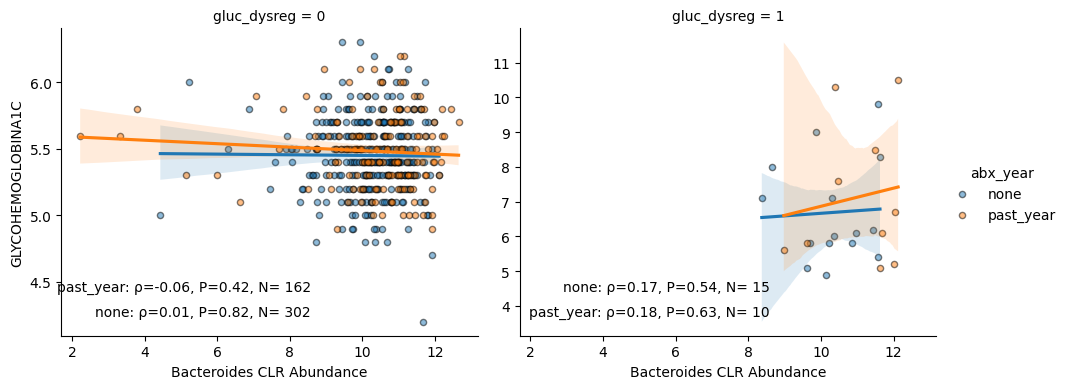

In [49]:
g = sns.lmplot(
    data=no_stat_no_gest_hx,
    x="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides",
    y="GLYCOHEMOGLOBINA1C",
    col="gluc_dysreg",
    #row="gluc_dysreg",    
    hue="abx_year",
    scatter_kws={
        "s": 20,
        "edgecolor": "black",
        "alpha": 0.5
    },
    facet_kws={"sharey": False},
    height=4,
    aspect=1.2
)
g.set_axis_labels("Bacteroides CLR Abundance")

# Loop through each facet
for (col_val), ax in g.axes_dict.items():
    facet_df = no_stat_no_gest_hx[(no_stat_no_gest_hx["gluc_dysreg"] == col_val)]
    y = 0.1   # starting height for annotations

    for hue_val in facet_df["abx_year"].unique():

        subset = facet_df[facet_df["abx_year"] == hue_val][[
                "Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides", "GLYCOHEMOGLOBINA1C"]].dropna()

        if len(subset) > 2:
            rho, p = spearmanr(subset["Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides"], subset["GLYCOHEMOGLOBINA1C"])
            n_hue = len(subset)

            ax.text(
                0.6, y,
                f"{hue_val}: ρ={rho:.2f}, P={p:.2g}, N={n_hue: .4g}",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=10
            )

            y += 0.08